# Is Claim Denial a Property of the Insurer or the Plan?
**ANLY 530 · KA1 Milestone 1** · Ankit Bisht

Research question: how much of the variation in claim denial rates across ACA Marketplace plans is attributable to the insurer rather than to the plan's design, and can publicly reported plan attributes predict a plan's denial rate for insurers not seen during training?

Data: CMS Transparency in Coverage Public Use File. One row is one individual-market medical plan; the target is the plan's in-network claim denial rate. The notebook downloads the public files from CMS on first run and caches them in `data/`.

In [1]:
import io, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold, GroupKFold, GridSearchCV
from sklearn.metrics import mean_absolute_error

SEED = 42
DATA = Path("data"); DATA.mkdir(exist_ok=True)

def load_puf(file_year):
    """CMS Transparency in Coverage PUF. The file for plan year Y reports claims for calendar year Y - 2."""
    local = DATA / f"transparency_in_coverage_puf_{file_year}.xlsx"
    if not local.exists():
        url = f"https://download.cms.gov/marketplace-puf/{file_year}/transparency-in-coverage-puf.zip"
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
        local.write_bytes(z.read([n for n in z.namelist() if n.lower().endswith(".xlsx")][0]))
    # Column names are on the third row; keep_default_na=False keeps CMS codes such as "N/A" visible
    return pd.read_excel(local, sheet_name=f"Transparency {file_year} - Ind QHP", header=2, keep_default_na=False)

raw = load_puf(2026)     # claims for calendar year 2024
prev = load_puf(2025)    # claims for calendar year 2023
print("2026 file (2024 claims):", raw.shape, "| 2025 file (2023 claims):", prev.shape)

2026 file (2024 claims): (4159, 44) | 2025 file (2023 claims): (4541, 44)


## 1. Data audit

In [2]:
REC, DEN = "Plan_Number_Claims_Received_In_Network", "Plan_Number_Claims_Denied_In_Network"
print("Plans:", len(raw), "| issuer IDs:", raw["Issuer_ID"].nunique(), "| states:", raw["State"].nunique())
print()
print("How the target's two columns are coded (CMS legend: * not available, ** suppressed small cell,")
print("*** not required for plan type, N/A issuer or plan new to the Exchange):")
codes = pd.DataFrame({c: raw[c].astype(str).where(raw[c].astype(str).isin(["N/A", "*", "**", "***", ""]), "number").value_counts()
                      for c in (REC, DEN)}).fillna(0).astype(int)
print(codes.to_string())

d = raw.copy()
for c in (REC, DEN):
    d[c] = pd.to_numeric(d[c], errors="coerce")
usable = (d[REC] > 0) & d[DEN].notna()
print()
print("Usable plans (claims received > 0 and denials reported):", int(usable.sum()), "of", len(d))
print("Constant columns:", [c for c in raw.columns if raw[c].nunique() == 1])

Plans: 4159 | issuer IDs: 185 | states: 30

How the target's two columns are coded (CMS legend: * not available, ** suppressed small cell,
*** not required for plan type, N/A issuer or plan new to the Exchange):
        Plan_Number_Claims_Received_In_Network  Plan_Number_Claims_Denied_In_Network
number                                    2554                                  2541
N/A                                       1600                                  1600
**                                           5                                    18

Usable plans (claims received > 0 and denials reported): 2527 of 4159
Constant columns: ['Individual/SHOP', 'SADP_Only', 'QHP or SADP?', 'Rate_Review']


In [3]:
# Do the plans we can use look like the ones we cannot?
for col in ["Plan_Type", "Metal_Level", "Exchange_Type"]:
    t = pd.crosstab(d[col], usable.map({True: "usable", False: "excluded"}), normalize="columns").round(3)
    print(f"--- {col} (column shares)"); print(t.to_string()); print()
print("Share of excluded plans whose insurer is new to the Exchange:",
      round((d.loc[~usable, "Is_Issuer_New_to_Exchange?(Yes_or_No)"] == "Yes").mean(), 3))

--- Plan_Type (column shares)
col_0      excluded  usable
Plan_Type                  
EPO           0.272   0.262
HMO           0.621   0.473
POS           0.044   0.137
PPO           0.064   0.128

--- Metal_Level (column shares)
col_0         excluded  usable
Metal_Level                   
Bronze           0.298   0.325
Catastrophic     0.015   0.030
Gold             0.271   0.300
Platinum         0.010   0.011
Silver           0.405   0.334

--- Exchange_Type (column shares)
col_0          excluded  usable
Exchange_Type                  
FFE               0.685   0.743
SBE-FP            0.028   0.026
SPE               0.287   0.231

Share of excluded plans whose insurer is new to the Exchange: 0.216


**What the audit shows.** The 2026 file covers 4,159 individual-market plans from 185 insurer IDs in 30 states. The target cannot be computed for 1,632 of them: 1,600 are coded "N/A" because the plan or insurer is new to the Exchange, and a few are suppressed for small counts. That leaves 2,527 usable plans (60.8%). Four columns are constant and carry no information.

The usable plans are not a random subset. Excluded plans are more often HMOs (62.1% against 47.3%) and Silver plans (40.5% against 33.4%), and 21.6% of them belong to insurers new to the Exchange. Results therefore describe the plans of established insurers. All claims figures are self-reported by insurers to CMS, and `Average Monthly Enrollment` is missing or suppressed for 23.1% of usable plans, so it enters the models with median imputation and a missing-value indicator fitted inside each training fold. Enrollment also does not reconcile with the claim counts: the median plan reports 453 claims per average monthly enrollee, far more than one person generates in a year, so the two are probably counted on different bases and enrollment is treated only as a rough size measure. Finally, the largest insurer accounts for 20.7% of usable plans, so folds grouped by insurer are uneven in size.

## 2. The target: plan-level denial rate

Plans: 2527 | issuers: 149 | states: 30
Claims received: 344,345,114 | denied: 65,578,278 | overall denial rate: 0.190
count    2527.000
mean        0.178
std         0.069
min         0.000
25%         0.139
50%         0.176
75%         0.213
max         0.874
Enrollment missing or suppressed in usable plans: 0.231
Median claims received per average monthly enrollee: 453
Largest insurer's share of usable plans: 0.207


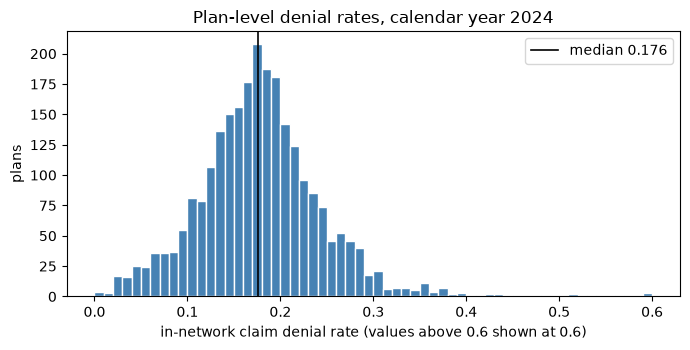

In [4]:
df = d[usable].reset_index(drop=True)
df["denial_rate"] = df[DEN] / df[REC]
df["enrollment"] = pd.to_numeric(df["Average Monthly Enrollment"], errors="coerce")   # '*' and '**' become missing
print("Plans:", len(df), "| issuers:", df["Issuer_ID"].nunique(), "| states:", df["State"].nunique())
print("Claims received:", f"{df[REC].sum():,.0f}", "| denied:", f"{df[DEN].sum():,.0f}",
      "| overall denial rate:", f"{df[DEN].sum() / df[REC].sum():.3f}")
print(df["denial_rate"].describe().round(3).to_string())
print("Enrollment missing or suppressed in usable plans:", round(df["enrollment"].isna().mean(), 3))
has_e = df["enrollment"] > 0
print("Median claims received per average monthly enrollee:", round((df.loc[has_e, REC] / df.loc[has_e, "enrollment"]).median()))
print("Largest insurer's share of usable plans:", round(df["Issuer_ID"].value_counts(normalize=True).iloc[0], 3))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(df["denial_rate"].clip(upper=0.6), bins=60, color="steelblue", edgecolor="white")
ax.axvline(df["denial_rate"].median(), color="black", lw=1.2, label=f"median {df['denial_rate'].median():.3f}")
ax.set_xlabel("in-network claim denial rate (values above 0.6 shown at 0.6)"); ax.set_ylabel("plans")
ax.set_title("Plan-level denial rates, calendar year 2024"); ax.legend()
plt.tight_layout(); plt.show()

In [5]:
# Descriptive comparison by plan attribute (unweighted plan means)
for col in ["Plan_Type", "Metal_Level", "Exchange_Type"]:
    t = df.groupby(col)["denial_rate"].agg(plans="size", mean="mean", median="median").round(3)
    print(f"--- {col}"); print(t.sort_values("mean", ascending=False).to_string()); print()

issuer = df.groupby("Issuer_ID").apply(lambda g: pd.Series({"plans": len(g), "rate": g[DEN].sum() / g[REC].sum()}),
                                       include_groups=False)
big = issuer[issuer["plans"] >= 5]
print(f"Issuer-level denial rate (issuers with 5+ usable plans, n = {len(big)}): "
      f"min {big['rate'].min():.3f}, median {big['rate'].median():.3f}, max {big['rate'].max():.3f}")

--- Plan_Type
           plans   mean  median
Plan_Type                      
EPO          661  0.194   0.188
HMO         1195  0.185   0.184
PPO          324  0.154   0.155
POS          347  0.149   0.147

--- Metal_Level
              plans   mean  median
Metal_Level                       
Catastrophic     76  0.184   0.180
Silver          843  0.183   0.178
Bronze          822  0.177   0.176
Gold            759  0.175   0.173
Platinum         27  0.161   0.172

--- Exchange_Type
               plans   mean  median
Exchange_Type                      
SPE              583  0.182   0.184
FFE             1878  0.179   0.176
SBE-FP            66  0.131   0.152

Issuer-level denial rate (issuers with 5+ usable plans, n = 139): min 0.027, median 0.192, max 0.410


## 3. Insurer or plan? Decomposing the variation

In [6]:
def share_explained(y, groups):
    """Eta-squared (between-group share of variance) and epsilon-squared, which corrects for the number of groups."""
    y = np.asarray(y); g = pd.Series(groups).astype(str).values
    sst = ((y - y.mean()) ** 2).sum()
    means = pd.Series(y).groupby(g).transform("mean").values
    ssb = ((means - y.mean()) ** 2).sum(); ssw = sst - ssb
    k, n = len(set(g)), len(y)
    return ssb / sst, (ssb - (k - 1) * ssw / (n - k)) / sst, k

rows = []
for col in ["Issuer_ID", "State", "Plan_Type", "Metal_Level", "Exchange_Type"]:
    eta, eps, k = share_explained(df["denial_rate"], df[col])
    rows.append({"grouping": col, "groups": k, "share of variance (eta^2)": eta, "corrected (epsilon^2)": eps})

# Within an insurer: how much do plan attributes add once the insurer is known?
within = df["denial_rate"] - df.groupby("Issuer_ID")["denial_rate"].transform("mean")
for col in ["Plan_Type", "Metal_Level"]:
    eta, eps, k = share_explained(within, df[col])
    sst_within = (within ** 2).sum(); sst_total = ((df["denial_rate"] - df["denial_rate"].mean()) ** 2).sum()
    rows.append({"grouping": f"{col}, within insurer", "groups": k,
                 "share of variance (eta^2)": eta * sst_within / sst_total, "corrected (epsilon^2)": eps * sst_within / sst_total})
print("Share of total variance in plan denial rates associated with each grouping (2,527 plans)")
pd.DataFrame(rows).set_index("grouping").round(3)

Share of total variance in plan denial rates associated with each grouping (2,527 plans)


,groups,share of variance (eta^2),corrected (epsilon^2)
grouping,,,
Issuer_ID,149,0.545,0.517
State,30,0.239,0.230
Plan_Type,4,0.060,0.059
Metal_Level,5,0.003,0.002
Exchange_Type,3,0.013,0.012
"Plan_Type, within insurer",4,0.006,0.005
"Metal_Level, within insurer",5,0.004,0.003


**What the descriptive results show.** Across 2,527 plans and 149 insurers, insurers received 344 million in-network claims and denied 65.6 million, an overall rate of 19.0%. The median plan denies 17.6%, and the middle half of plans fall between 13.9% and 21.3%. By plan type, EPOs (19.4%) and HMOs (18.5%) deny more than PPOs (15.4%) and POS plans (14.9%), while metal levels barely differ (17.5% to 18.3%, apart from 27 Platinum plans at 16.1%). Insurers differ far more: among the 139 insurers with five or more usable plans, denial rates run from 2.7% to 41.0%.

**Insurer or plan?** Insurer identity is associated with 54.5% of the variance in plan denial rates (51.7% after correcting for the 149 groups). Plan type accounts for 6.0%, metal level for 0.3% and exchange type for 1.3%. State reaches 23.9%, but this is likely inflated because each state has relatively few insurers, so knowing the state partly reveals the insurer.

The within-insurer rows give the key result. Once the insurer is known, plan type accounts for only 0.6% of the total variance and metal level for 0.4%. The plan-type gap above therefore mostly reflects *which insurers* offer HMOs and EPOs rather than the plan design itself. In this data, denial behavior is predominantly a property of the insurer. These are descriptive associations, not causal effects.

## 4. Can public plan attributes predict denial rates for unseen insurers?

In [7]:
# Prior-year insurer denial rate (2023 claims, 2025 file) is public before the year starts, so it is a legitimate predictor.
p = prev.copy()
for c in ("Issuer_Claims_Received_In_Network", "Issuer_Claims_Denied_In_Network"):
    p[c] = pd.to_numeric(p[c], errors="coerce")
p = p.drop_duplicates("Issuer_ID")
p = p[p["Issuer_Claims_Received_In_Network"] > 0]
prior = (p.set_index("Issuer_ID")["Issuer_Claims_Denied_In_Network"] / p.set_index("Issuer_ID")["Issuer_Claims_Received_In_Network"])
df["prior_issuer_rate"] = df["Issuer_ID"].map(prior)
print("Usable 2024 plans whose insurer reported 2023 claims:", round(df["prior_issuer_rate"].notna().mean(), 3))

cur = df.groupby("Issuer_ID").apply(lambda g: g[DEN].sum() / g[REC].sum(), include_groups=False)
both = pd.concat([prior.rename("2023"), cur.rename("2024")], axis=1, join="inner").dropna()
print(f"Insurers with rates in both years: {len(both)} | correlation of 2023 and 2024 insurer denial rates: "
      f"{both['2023'].corr(both['2024']):.3f}")
change = (both["2024"] - both["2023"]).abs()
print(f"Year-to-year change in insurer rate: median {change.median():.3f}; share of insurers moving more than 0.05: {(change > 0.05).mean():.2f}")
m = df["prior_issuer_rate"].notna()
print(f"Plan-level correlation of prior-year insurer rate with 2024 plan rate: {df.loc[m, 'prior_issuer_rate'].corr(df.loc[m, 'denial_rate']):.3f}")
print(f"MAE if each plan is predicted by its insurer's 2023 rate: {mean_absolute_error(df.loc[m, 'denial_rate'], df.loc[m, 'prior_issuer_rate']):.4f}"
      f" | MAE of the overall mean on the same plans: {mean_absolute_error(df.loc[m, 'denial_rate'], np.full(m.sum(), df.loc[m, 'denial_rate'].mean())):.4f}")

PLAN_CAT = ["Plan_Type", "Metal_Level", "Exchange_Type"]
log_enroll = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), FunctionTransformer(np.log1p), StandardScaler())

def design(cat, num_extra=()):
    parts = [("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("enroll", log_enroll, ["enrollment"])]
    if num_extra:
        parts.append(("extra", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), list(num_extra)))
    return ColumnTransformer(parts)

def ridge(cat, extra=()):
    # alpha is tuned inside each training fold with inner folds grouped by insurer
    return GridSearchCV(Pipeline([("prep", design(cat, extra)), ("m", Ridge())]),
                        {"m__alpha": [0.1, 1, 10, 100, 1000]}, cv=GroupKFold(4), scoring="neg_mean_absolute_error")

candidates = {
    "Ridge: plan attributes":                    (ridge(PLAN_CAT), True),
    "Ridge: plan attributes + State":            (ridge(PLAN_CAT + ["State"]), True),
    "Gradient boosting: plan attributes + State": (Pipeline([("prep", design(PLAN_CAT + ["State"])),
                                                   ("m", GradientBoostingRegressor(n_estimators=300, random_state=SEED))]), False),
    "Ridge: plan attributes + prior-year insurer rate": (ridge(PLAN_CAT, ["prior_issuer_rate"]), True),
}
X = df[PLAN_CAT + ["State", "enrollment", "prior_issuer_rate"]]
y, groups = df["denial_rate"].values, df["Issuer_ID"].values

Usable 2024 plans whose insurer reported 2023 claims: 0.978
Insurers with rates in both years: 141 | correlation of 2023 and 2024 insurer denial rates: 0.518
Year-to-year change in insurer rate: median 0.031; share of insurers moving more than 0.05: 0.35
Plan-level correlation of prior-year insurer rate with 2024 plan rate: 0.260


MAE if each plan is predicted by its insurer's 2023 rate: 0.0670 | MAE of the overall mean on the same plans: 0.0494


In [8]:
designs = {"random 5-fold": list(KFold(5, shuffle=True, random_state=SEED).split(X)),
           "grouped by insurer": list(GroupKFold(5).split(X, y, groups))}
res = {}
for dname, folds in designs.items():
    base = [mean_absolute_error(y[te], np.full(len(te), y[tr].mean())) for tr, te in folds]   # fold-mean baseline
    res[("Baseline: training-fold mean", dname)] = base
    for name, (model, grouped_tuning) in candidates.items():
        errs = []
        for tr, te in folds:
            kw = {"groups": groups[tr]} if grouped_tuning else {}
            fit = model.fit(X.iloc[tr], y[tr], **kw)
            errs.append(mean_absolute_error(y[te], fit.predict(X.iloc[te])))
        res[(name, dname)] = errs

summary = pd.DataFrame({k: {"MAE": np.mean(v), "SD": np.std(v)} for k, v in res.items()}).T.unstack(1)
summary.columns = [f"{m} ({dn})" for m, dn in summary.columns]
summary = summary[["MAE (random 5-fold)", "MAE (grouped by insurer)", "SD (grouped by insurer)"]]
summary["optimism (grouped - random)"] = summary["MAE (grouped by insurer)"] - summary["MAE (random 5-fold)"]
gb = summary.loc["Baseline: training-fold mean", "MAE (grouped by insurer)"]
summary["vs baseline (grouped)"] = summary["MAE (grouped by insurer)"] - gb
print("Mean absolute error in denial-rate units (0.01 = 1 percentage point); negative 'vs baseline' = better than baseline")
summary.round(4)

Mean absolute error in denial-rate units (0.01 = 1 percentage point); negative 'vs baseline' = better than baseline


,MAE (random 5-fold),MAE (grouped by insurer),SD (grouped by insurer),optimism (grouped - random),vs baseline (grouped)
Baseline: training-fold mean,0.0495,0.0506,0.0074,0.0011,0.0000
Gradient boosting: plan attributes + State,0.0386,0.0664,0.0122,0.0278,0.0158
Ridge: plan attributes,0.0473,0.0503,0.0078,0.0030,-0.0003
Ridge: plan attributes + State,0.0473,0.0522,0.0052,0.0048,0.0016
Ridge: plan attributes + prior-year insurer rate,0.0453,0.0504,0.0069,0.0051,-0.0002


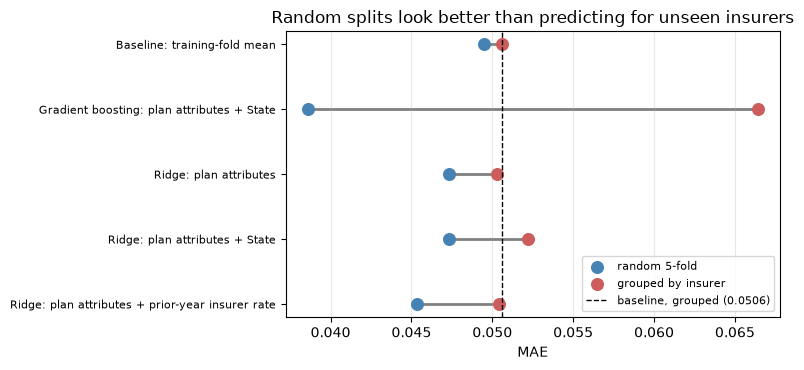

In [9]:
labels = list(summary.index)
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, k in enumerate(labels):
    r, g = summary.loc[k, "MAE (random 5-fold)"], summary.loc[k, "MAE (grouped by insurer)"]
    ax.plot([r, g], [i, i], color="grey", lw=2, zorder=1)
    ax.scatter(r, i, color="steelblue", s=70, zorder=2, label="random 5-fold" if i == 0 else None)
    ax.scatter(g, i, color="indianred", s=70, zorder=2, label="grouped by insurer" if i == 0 else None)
ax.axvline(gb, color="black", ls="--", lw=1, label=f"baseline, grouped ({gb:.4f})")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("MAE"); ax.set_title("Random splits look better than predicting for unseen insurers")
ax.legend(fontsize=8, loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

**What the prediction experiment shows.** The metric is mean absolute error in the target's own units (Itauma, 2026, Section 16.32, p. 466): 0.01 is one percentage point.

Under random 5-fold splitting every model beats the baseline, and gradient boosting looks best (0.0386 against 0.0495). That design lets plans from the same insurer appear in both training and test folds. The realistic question, predicting for insurers the model has not seen, needs folds grouped by insurer (Roberts et al., 2017; Itauma, 2026, Sections 16.73-16.74, p. 482). Under grouped folds the picture reverses:

- Gradient boosting falls to 0.0664, 1.6 percentage points *worse* than predicting the training mean. It has the largest gap between the two designs (0.0278), the signature of a model memorizing insurers.
- Ridge regression on plan attributes reaches 0.0503 against a baseline of 0.0506. The 0.0003 difference is tiny next to the fold-to-fold standard deviation of 0.0078, so it is not a real improvement.
- Adding State makes ridge worse (0.0522), consistent with State acting as a partial insurer identifier.
- Insurer denial rates are only moderately stable. Across 141 insurers the 2023 and 2024 rates correlate at 0.518, but the median insurer moved by 3.1 percentage points and 35% moved by more than 5. At the plan level the correlation is just 0.260, and predicting each plan by its insurer's 2023 rate gives an MAE of 0.0670, worse than the overall mean (0.0494). This explains why adding the prior-year rate does not beat the baseline for unseen insurers (0.0504). It helps only under random splits (0.0453), where it works as an insurer fingerprint.

So the answer to the prediction question, at this stage, is no: publicly reported plan attributes do not predict denial rates for insurers outside the training data. This is consistent with the decomposition, since the attributes that are available explain little of the insurer-level variation that drives denial rates.

## 5. Summary and next steps

**Findings so far.**
1. Denial behavior is predominantly an insurer property: insurer identity is associated with about half of the variance in plan denial rates, while plan type and metal level add less than 1% once the insurer is known.
2. Public plan attributes do not predict denial rates for unseen insurers. The best model ties the baseline, and flexible models do worse.
3. Random splitting would have produced the opposite conclusion. The evaluation design, not the algorithm, decides the answer.

**Plan for Milestone 2.**
1. Temporal validation: train on 2023 claims (2025 file) and predict 2024 claims, matching plans by `Plan_ID`. This is the realistic use: predicting next year from what is public now.
2. Test whether insurer history can be used more effectively: plan-level prior-year rates, claim-volume weighting and non-linear terms.
3. Check whether excluding new and suppressed plans biases the conclusions.
4. Translate the findings for the three audiences: what consumers, regulators and hospitals can and cannot infer from the public file.

**References**

Centers for Medicare & Medicaid Services. (2025). *Transparency in coverage public use files, plan years 2025 and 2026* [Data sets]. https://www.cms.gov/marketplace/resources/data/public-use-files

Itauma, I. (2026). *Machine learning using Python: Foundations, algorithms, applications, and reproducible research* (2nd ed.).

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

**AI use.** The code and text in this notebook were generated with Claude (Anthropic), building on the analyses from my Weeks 4–8 discussion posts.